# Import Library

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import shutil
import cv2
import torch
import pandas as pd
from sklearn.model_selection import train_test_split
from torchvision import transforms

device = torch.device("cuda")

# Clear folder output

In [ ]:
working_dir = '/kaggle/working'

for item in os.listdir(working_dir):
    item_path = os.path.join(working_dir, item)
    if os.path.isfile(item_path):
        os.remove(item_path)
    elif os.path.isdir(item_path):
        shutil.rmtree(item_path)

print("Output folder cleared")

Output folder cleared


# Cek isi dataset

In [ ]:
input_dir = '/kaggle/input/datasets/aryashah2k/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT'

labels = ['benign', 'malignant', 'normal']

benign: 891 gambar
malignant: 421 gambar
normal: 266 gambar


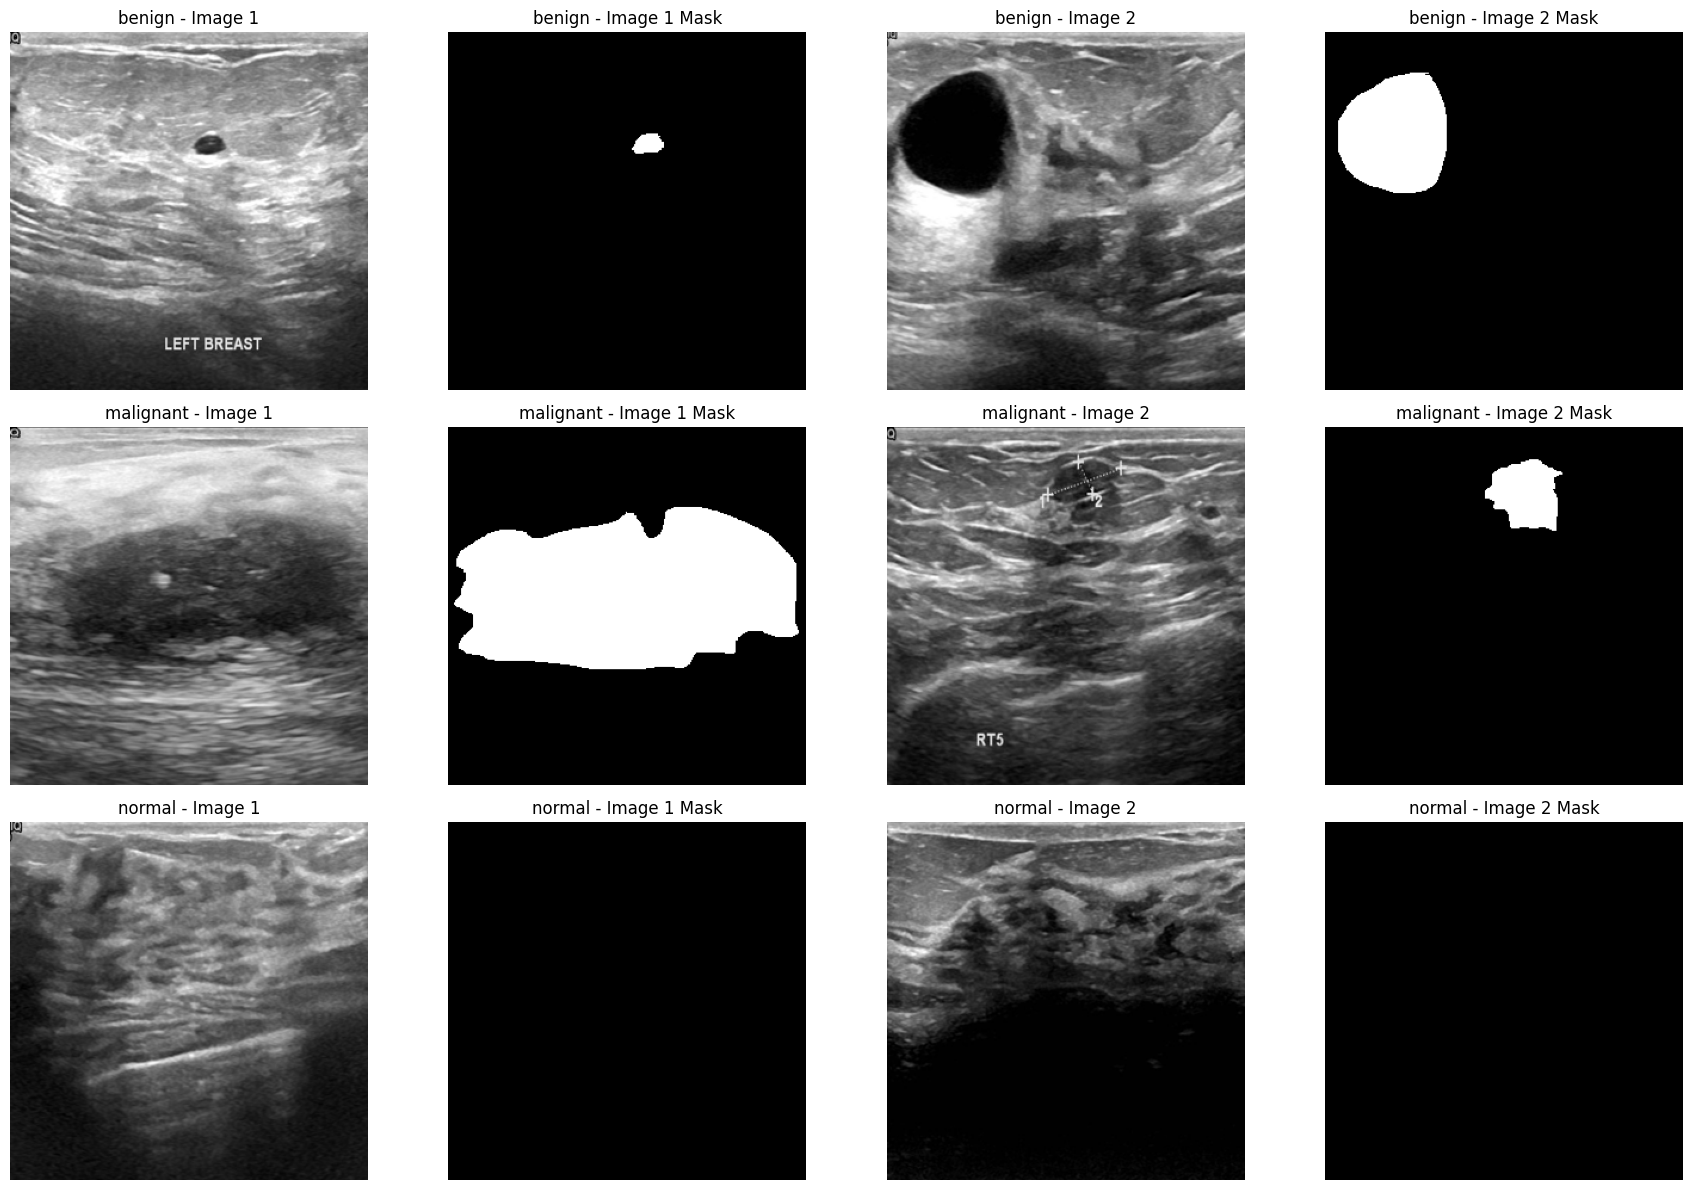

In [ ]:
for label in labels:
    folder = os.path.join(input_dir, label)
    jumlah = len([f for f in os.listdir(folder) if f.endswith('.png')])
    print(f"{label}: {jumlah} gambar")

fig, axs = plt.subplots(3, 4, figsize=(18, 12))

for i, label in enumerate(labels):
    label_dir = os.path.join(input_dir, label)
    image_files = sorted([f for f in os.listdir(label_dir) if f.endswith('.png')])
    for j in range(4):
        if j < len(image_files):
            image_path = os.path.join(label_dir, image_files[j])
            image = Image.open(image_path)
            image = image.resize((300,300))
            if j % 2 == 0:
                image_label = f'{label} - Image {j//2+1}'
            else:
                image_label = f'{label} - Image {j//2+1} Mask'
            axs[i, j].imshow(image, cmap='gray' if 'mask' in image_label.lower() else None)
            axs[i, j].set_title(image_label)
            axs[i, j].axis('off')

plt.tight_layout()
plt.show()

# Preprocessing: Image Enhancement (Unsharp masking, Gaussian, Median) dan Feature Extraction (Sobel, Canny)
<h4>Unsharp masking dengan Blurring dan edge detection</h4>
<h4>Citra ultrasound -> Grayscale -> RGB -> Blurring -> Unsharp Masking -> edge detection -> Output</h4>

In [ ]:
def unsharpMasking(img, sigma=1.0, strength=1.0):
    img_np = np.array(img, dtype=np.float64)
    blurred = cv2.GaussianBlur(img_np, (0, 0), sigma)
    sharpened = cv2.addWeighted(img_np, 1.0 + strength, blurred, -strength, 0)
    sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)
    return Image.fromarray(sharpened)

def sobelEdge(img, weight=0.2):
    img_np = np.array(img, dtype=np.float64)
    sobel_x = cv2.Sobel(img_np, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(img_np, cv2.CV_64F, 0, 1, ksize=3)
    sobel_mag = np.sqrt(sobel_x**2 + sobel_y**2)
    enhanced = cv2.addWeighted(img_np, 1.0, sobel_mag, weight, 0)
    enhanced = np.clip(enhanced, 0, 255).astype(np.uint8)
    return Image.fromarray(enhanced)

In [ ]:
def preprocessing_baseline(img):
    return img

In [ ]:
def preprocessing_gaussian_sobel(img):
    img_np = np.array(img)
    if len(img_np.shape) == 3 and img_np.shape[2] == 3:
        img_gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    else:
        img_gray = img_np
    img_rgb = cv2.cvtColor(img_gray, cv2.COLOR_GRAY2RGB)
    img_rgb = unsharpMasking(img_rgb)
    img_rgb = sobelEdge(img_rgb)
    return img_rgb

In [ ]:
def preprocessing_gaussian_canny(img):
    img_np = np.array(img)
    if len(img_np.shape) == 3:
        img_gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    else:
        img_gray = img_np

    img_blur = cv2.GaussianBlur(img_gray, (3, 3), 0.5)
    edges = cv2.Canny(img_blur, 50, 150)
    img_rgb = cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB)
    img_rgb = unsharpMasking(img_rgb)
    return img_rgb

In [ ]:
def preprocessing_median_sobel(img):
    img_np = np.array(img)
    if len(img_np.shape) == 3:
        img_gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    else:
        img_gray = img_np
    img_blur = cv2.medianBlur(img_gray, 3)
    img_rgb = cv2.cvtColor(img_blur, cv2.COLOR_GRAY2RGB)
    img_rgb = unsharpMasking(img_rgb)
    img_rgb = sobelEdge(img_rgb)
    return img_rgb

# Preprocessing: Data Transformation dan Augmentation
<h4>- Resize image: Ubah ukuran image ke 256x256</h4>
<h4>- Centercrop(224): Memotong bagian tengah gambar agar ukurannya jadi 224×224 (DenseNet perlu input 224×224).</h4>
<h4>- RandomHorizontalFlip(0.9):  Membalik gambar kiri-kanan dengan peluang 90% -> model tidak bergantung pada posisi tumor di sisi tertentu.</h4>
<h4>- RandomRotation(15): Rotasi gambar 15 derajat secara acak -> model mengenali tumor dari berbagai sudut</h4>
<h4>- ColorJitter: Ubah brightness, contrast, saturation, hue</h4>
<h4>- Normalize: Menyesuaikan nilai pixel gambar dengan standar ImageNet (pretrained DenseNet121)</h4>

In [ ]:
from torchvision import transforms
from torchvision.transforms import RandomHorizontalFlip, RandomRotation, ColorJitter
import random

classes = ['malignant', 'normal', 'benign']

augmentation = transforms.Compose([
    RandomHorizontalFlip(p=0.9),
    RandomRotation(15),
    ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
])

In [ ]:
def create_data_transforms(preproc_func):
    data_transforms = {
        'train': transforms.Compose([
            transforms.Lambda(preproc_func),
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.RandomApply([augmentation], p=0.5),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ]),
        'validation': transforms.Compose([
            transforms.Lambda(preproc_func),
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ]),
        'test': transforms.Compose([
            transforms.Lambda(preproc_func),
            transforms.Resize(256),
            transforms.CenterCrop(224),
            transforms.ToTensor(),
            transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
        ]),
    }
    return data_transforms

# Split data
<h4>Dataset overlay dibagi menjadi train (70%), validation (15%), test (15%) dan disalin ke folder masing-masing.</h4>
<h4>Baca file -> split data dengan 'train_test_split' -> buat subfolder masing-masing class, copy file ke folder masing-masing class</h4>

In [ ]:
file_paths = []
labels_list = []

for label in os.listdir(input_dir):
    label_dir = os.path.join(input_dir, label)
    if os.path.isdir(label_dir):
        for f in os.listdir(label_dir):
            if f.endswith('.png') and '_mask' not in f:
                file_paths.append(os.path.join(label_dir, f))
                labels_list.append(label)

df = pd.DataFrame({'Image_Path': file_paths, 'Label': labels_list})
print(f"Total original image: {len(df)}")
print(df['Label'].value_counts())

Total original image: 780
Label
benign       437
malignant    210
normal       133
Name: count, dtype: int64


In [ ]:
train_data, test_data = train_test_split(df, test_size=0.15, random_state=42, stratify=df['Label'])
train_data, val_data = train_test_split(train_data, test_size=0.15/0.85, random_state=42, stratify=train_data['Label'])

print(f"\nTrain: {len(train_data)}, Validation: {len(val_data)}, Test: {len(test_data)}")

def prepare_folders_and_copy(scenario_name, train_data, val_data, test_data, df):
    for split in ['train', 'validation', 'test']:
        for label in df['Label'].unique():
            os.makedirs(f'/kaggle/working/{scenario_name}/{split}/{label}', exist_ok=True)

    for split_name, split_data in [('train', train_data), ('validation', val_data), ('test', test_data)]:
        split_dir = f'/kaggle/working/{scenario_name}/{split_name}'
        for _, row in split_data.iterrows():
            dst = os.path.join(split_dir, row['Label'], os.path.basename(row['Image_Path']))
            shutil.copy2(row['Image_Path'], dst)


Train: 545, Validation: 118, Test: 117


# ImageNet & Dataloader
<h5>Siapin data yang akan dimasukkan ke model</h5>

In [ ]:
from torch.utils.data import DataLoader
from torchvision.datasets import ImageFolder

def create_dataloaders(scenario_name, data_transforms):
    image_datasets = {
        x: ImageFolder(root=f'/kaggle/working/{scenario_name}/{x}', transform=data_transforms[x])
        for x in ['train', 'validation', 'test']
    }
    dataloaders = {
        x: DataLoader(image_datasets[x], batch_size=8, shuffle=True, num_workers=2)
        for x in ['train', 'validation', 'test']
    }
    dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'validation', 'test']}
    class_names = image_datasets['train'].classes
    return dataloaders, dataset_sizes, class_names

# Training Function dengan early stopping
<h4>Parameter:</h4>
<h4>- Epoch = 20</h4>
<h4>- Patience = 4 (early stop kalau validation loss ga turun selama 4 epoch)</h4>
<h4>- Optimizer = Adam (learning rate = 0.00005)</h4>
<h4>- Scheduler = StepLR</h4>
<h4>- Loss Function = CrossEntropyLoss</h4>

In [ ]:
import copy

def train_model(model, loss_fn, optimizer, scheduler, dataloaders, dataset_sizes, device, epochs=20, patience=4):
    best_loss = float('inf')
    best_weights = None
    no_improve = 0

    for epoch in range(epochs):
        print(f'Epoch {epoch+1}/{epochs}')
        for phase in ['train', 'validation']:
            model.train() if phase == 'train' else model.eval()
            loss_sum = 0.0
            correct = 0
            for inputs, labels in dataloaders[phase]:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = loss_fn(outputs, labels)
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()
                loss_sum += loss.item() * inputs.size(0)
                correct += torch.sum(preds == labels.data)
            if phase == 'train':
                scheduler.step()
            avg_loss = loss_sum / dataset_sizes[phase]
            acc = correct.double() / dataset_sizes[phase]
            print(f'{phase} Loss: {avg_loss:.4f} Acc: {acc:.4f}')
            if phase == 'validation':
                if avg_loss < best_loss:
                    best_loss = avg_loss
                    best_weights = copy.deepcopy(model.state_dict())
                    no_improve = 0
                else:
                    no_improve += 1
        if no_improve >= patience:
            print(f"Early stopping di epoch {epoch+1}")
            break
        print()

    if best_weights:
        model.load_state_dict(best_weights)
    return model

# Training DenseNet

In [ ]:
import torch.optim as optim
from torch.optim import lr_scheduler
import torch.nn as nn
import torchvision.models as models

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

def evaluate_model(model, dataloaders, device, scenario_name):
    y_true, y_pred = [], []
    model.eval()
    with torch.no_grad():
        for inputs, labels in dataloaders['test']:
            inputs, labels = inputs.to(device), labels.to(device)
            preds = model(inputs).argmax(1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average=None)
    recall = recall_score(y_true, y_pred, average=None)
    f1 = f1_score(y_true, y_pred, average=None)
    cm = confusion_matrix(y_true, y_pred)

    print(f"{scenario_name} - Accuracy: {acc*100:.2f}%")

    return {'accuracy': acc, 'precision': precision, 'recall': recall, 'f1': f1, 'cm': cm}

In [ ]:
scenario_name = "Baseline"
prepare_folders_and_copy(scenario_name, train_data, val_data, test_data, df)
data_transforms = create_data_transforms(preprocessing_baseline)
dataloaders, dataset_sizes, class_names = create_dataloaders(scenario_name, data_transforms)

model_baseline = models.densenet121(pretrained=True)
model_baseline.classifier = nn.Linear(model_baseline.classifier.in_features, len(class_names))
model_baseline = model_baseline.to(device)
optimizer = optim.Adam(model_baseline.parameters(), lr=0.00005)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
Loss_Function = nn.CrossEntropyLoss()

model_baseline = train_model(model_baseline, Loss_Function, optimizer, scheduler, dataloaders, dataset_sizes, device)
results_baseline = evaluate_model(model_baseline, dataloaders, device, "Baseline")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 45.2MB/s]


Epoch 1/20
train Loss: 0.8488 Acc: 0.6037
validation Loss: 0.6712 Acc: 0.7034

Epoch 2/20
train Loss: 0.6183 Acc: 0.7688
validation Loss: 0.5556 Acc: 0.8051

Epoch 3/20
train Loss: 0.4829 Acc: 0.8312
validation Loss: 0.4502 Acc: 0.8475

Epoch 4/20
train Loss: 0.4041 Acc: 0.8495
validation Loss: 0.4007 Acc: 0.8644

Epoch 5/20
train Loss: 0.3571 Acc: 0.8606
validation Loss: 0.3779 Acc: 0.8729

Epoch 6/20
train Loss: 0.3103 Acc: 0.8789
validation Loss: 0.3523 Acc: 0.8729

Epoch 7/20
train Loss: 0.2566 Acc: 0.9284
validation Loss: 0.3739 Acc: 0.8475

Epoch 8/20
train Loss: 0.2108 Acc: 0.9358
validation Loss: 0.3364 Acc: 0.8729

Epoch 9/20
train Loss: 0.1947 Acc: 0.9486
validation Loss: 0.3229 Acc: 0.8644

Epoch 10/20
train Loss: 0.2105 Acc: 0.9413
validation Loss: 0.3500 Acc: 0.8644

Epoch 11/20
train Loss: 0.1697 Acc: 0.9578
validation Loss: 0.3292 Acc: 0.8644

Epoch 12/20
train Loss: 0.1721 Acc: 0.9560
validation Loss: 0.3269 Acc: 0.8729

Epoch 13/20
train Loss: 0.1786 Acc: 0.9468
valida

In [ ]:
scenario_name = "Gaussian_Sobel"
prepare_folders_and_copy(scenario_name, train_data, val_data, test_data, df)
data_transforms = create_data_transforms(preprocessing_gaussian_sobel)
dataloaders, dataset_sizes, class_names = create_dataloaders(scenario_name, data_transforms)

model_g_sobel = models.densenet121(pretrained=True)
model_g_sobel.classifier = nn.Linear(model_g_sobel.classifier.in_features, len(class_names))
model_g_sobel = model_g_sobel.to(device)

optimizer = optim.Adam(model_g_sobel.parameters(), lr=0.00005)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
Loss_Function = nn.CrossEntropyLoss()

model_g_sobel = train_model(model_g_sobel, Loss_Function, optimizer, scheduler, dataloaders, dataset_sizes, device)
results_gaussian_sobel = evaluate_model(model_g_sobel, dataloaders, device, "Gaussian+Sobel")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch 1/20
train Loss: 0.9106 Acc: 0.5651
validation Loss: 0.6949 Acc: 0.6864

Epoch 2/20
train Loss: 0.6154 Acc: 0.7541
validation Loss: 0.5770 Acc: 0.7712

Epoch 3/20
train Loss: 0.4678 Acc: 0.8495
validation Loss: 0.5242 Acc: 0.7797

Epoch 4/20
train Loss: 0.3951 Acc: 0.8495
validation Loss: 0.4699 Acc: 0.8305

Epoch 5/20
train Loss: 0.3292 Acc: 0.8954
validation Loss: 0.4281 Acc: 0.8305

Epoch 6/20
train Loss: 0.2901 Acc: 0.9009
validation Loss: 0.3983 Acc: 0.8305

Epoch 7/20
train Loss: 0.2316 Acc: 0.9284
validation Loss: 0.4212 Acc: 0.8305

Epoch 8/20
train Loss: 0.1715 Acc: 0.9468
validation Loss: 0.3950 Acc: 0.8305

Epoch 9/20
train Loss: 0.2006 Acc: 0.9358
validation Loss: 0.4068 Acc: 0.8390

Epoch 10/20
train Loss: 0.1868 Acc: 0.9431
validation Loss: 0.4150 Acc: 0.8390

Epoch 11/20
train Loss: 0.1635 Acc: 0.9523
validation Loss: 0.4053 Acc: 0.8390

Epoch 12/20
train Loss: 0.1743 Acc: 0.9431
validation Loss: 0.4420 Acc: 0.8390
Early stopping di epoch 12
Gaussian+Sobel - Accura

In [ ]:
scenario_name = "Gaussian_Canny"
prepare_folders_and_copy(scenario_name, train_data, val_data, test_data, df)
data_transforms = create_data_transforms(preprocessing_gaussian_canny)
dataloaders, dataset_sizes, class_names = create_dataloaders(scenario_name, data_transforms)

model_g_canny = models.densenet121(pretrained=True)
model_g_canny.classifier = nn.Linear(model_g_canny.classifier.in_features, len(class_names))
model_g_canny = model_g_canny.to(device)
optimizer = optim.Adam(model_g_canny.parameters(), lr=0.00005)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
Loss_Function = nn.CrossEntropyLoss()

model_g_canny = train_model(model_g_canny, Loss_Function, optimizer, scheduler, dataloaders, dataset_sizes, device)
results_gaussian_canny = evaluate_model(model_g_canny, dataloaders, device, "Gaussian+Canny")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch 1/20
train Loss: 1.0002 Acc: 0.5083
validation Loss: 0.8205 Acc: 0.6102

Epoch 2/20
train Loss: 0.7883 Acc: 0.6606
validation Loss: 0.7804 Acc: 0.6780

Epoch 3/20
train Loss: 0.6515 Acc: 0.7284
validation Loss: 0.7679 Acc: 0.6695

Epoch 4/20
train Loss: 0.5732 Acc: 0.7853
validation Loss: 0.7831 Acc: 0.6695

Epoch 5/20
train Loss: 0.4839 Acc: 0.8440
validation Loss: 0.7716 Acc: 0.7034

Epoch 6/20
train Loss: 0.4047 Acc: 0.8624
validation Loss: 0.7804 Acc: 0.6695

Epoch 7/20
train Loss: 0.3874 Acc: 0.8606
validation Loss: 0.7728 Acc: 0.6441
Early stopping di epoch 7
Gaussian+Canny - Accuracy: 69.23%


In [ ]:
scenario_name = "Median_Sobel"
prepare_folders_and_copy(scenario_name, train_data, val_data, test_data, df)
data_transforms = create_data_transforms(preprocessing_median_sobel)
dataloaders, dataset_sizes, class_names = create_dataloaders(scenario_name, data_transforms)

model_m_sobel = models.densenet121(pretrained=True)
model_m_sobel.classifier = nn.Linear(model_m_sobel.classifier.in_features, len(class_names))
model_m_sobel = model_m_sobel.to(device)
optimizer = optim.Adam(model_m_sobel.parameters(), lr=0.00005)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)
Loss_Function = nn.CrossEntropyLoss()

model_m_sobel = train_model(model_m_sobel, Loss_Function, optimizer, scheduler, dataloaders, dataset_sizes, device)
results_median_sobel = evaluate_model(model_m_sobel, dataloaders, device, "Median+Sobel")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DenseNet121_Weights.IMAGENET1K_V1`. You can also use `weights=DenseNet121_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch 1/20
train Loss: 0.9255 Acc: 0.5413
validation Loss: 0.6547 Acc: 0.7034

Epoch 2/20
train Loss: 0.6088 Acc: 0.7651
validation Loss: 0.5754 Acc: 0.7458

Epoch 3/20
train Loss: 0.5069 Acc: 0.8018
validation Loss: 0.5188 Acc: 0.7966

Epoch 4/20
train Loss: 0.3981 Acc: 0.8532
validation Loss: 0.4781 Acc: 0.7966

Epoch 5/20
train Loss: 0.3298 Acc: 0.8752
validation Loss: 0.4156 Acc: 0.8559

Epoch 6/20
train Loss: 0.2879 Acc: 0.8899
validation Loss: 0.4098 Acc: 0.8475

Epoch 7/20
train Loss: 0.2630 Acc: 0.9211
validation Loss: 0.4417 Acc: 0.8475

Epoch 8/20
train Loss: 0.2094 Acc: 0.9358
validation Loss: 0.4004 Acc: 0.8729

Epoch 9/20
train Loss: 0.2111 Acc: 0.9431
validation Loss: 0.4011 Acc: 0.8559

Epoch 10/20
train Loss: 0.2016 Acc: 0.9413
validation Loss: 0.3901 Acc: 0.8559

Epoch 11/20
train Loss: 0.1941 Acc: 0.9431
validation Loss: 0.4152 Acc: 0.8644

Epoch 12/20
train Loss: 0.2096 Acc: 0.9358
validation Loss: 0.4000 Acc: 0.8559

Epoch 13/20
train Loss: 0.2067 Acc: 0.9321
valida

# Model Evaluation
<h4>Accuracy, Precision per class, Recall per class, F1-score per class, Confusion matrix, Classification Report</h4>

In [ ]:
print("Baseline Acc:", results_baseline['accuracy'])
print("Gaussian+Sobel Acc:", results_gaussian_sobel['accuracy'])
print("Gaussian+Canny Acc:", results_gaussian_canny['accuracy'])
print("Median+Sobel Acc:", results_median_sobel['accuracy'])

Baseline Acc: 0.8803418803418803
Gaussian+Sobel Acc: 0.905982905982906
Gaussian+Canny Acc: 0.6923076923076923
Median+Sobel Acc: 0.8376068376068376


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

def evaluate_model(model, dataloaders, device, scenario_name):
    y_true, y_pred = [], []
    model.eval()
    with torch.no_grad():
        for inputs, labels in dataloaders['test']:
            inputs, labels = inputs.to(device), labels.to(device)
            preds = model(inputs).argmax(1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average=None)
    recall = recall_score(y_true, y_pred, average=None)
    f1 = f1_score(y_true, y_pred, average=None)
    cm = confusion_matrix(y_true, y_pred)

    print(f"HASIL EVALUASI: {scenario_name}")
    print(f"Accuracy: {acc*100:.2f}%\n")

    target_names = ['benign', 'malignant', 'normal']
    print("Classification Report:")
    print(classification_report(y_true, y_pred, target_names=target_names))

    return {'accuracy': acc, 'precision': precision, 'recall': recall, 'f1': f1, 'cm': cm}

Perbandingan 4 skenario: 

Baseline:
Accuracy: 88.03%
Malignant - Precision: 86.21%, Recall: 80.65%, F1: 83.33%

Gaussian+Sobel:
Accuracy: 90.60%
Malignant - Precision: 90.00%, Recall: 87.10%, F1: 88.52%

Gaussian+Canny:
Accuracy: 69.23%
Malignant - Precision: 61.76%, Recall: 67.74%, F1: 64.62%

Median+Sobel:
Accuracy: 83.76%
Malignant - Precision: 78.79%, Recall: 83.87%, F1: 81.25%



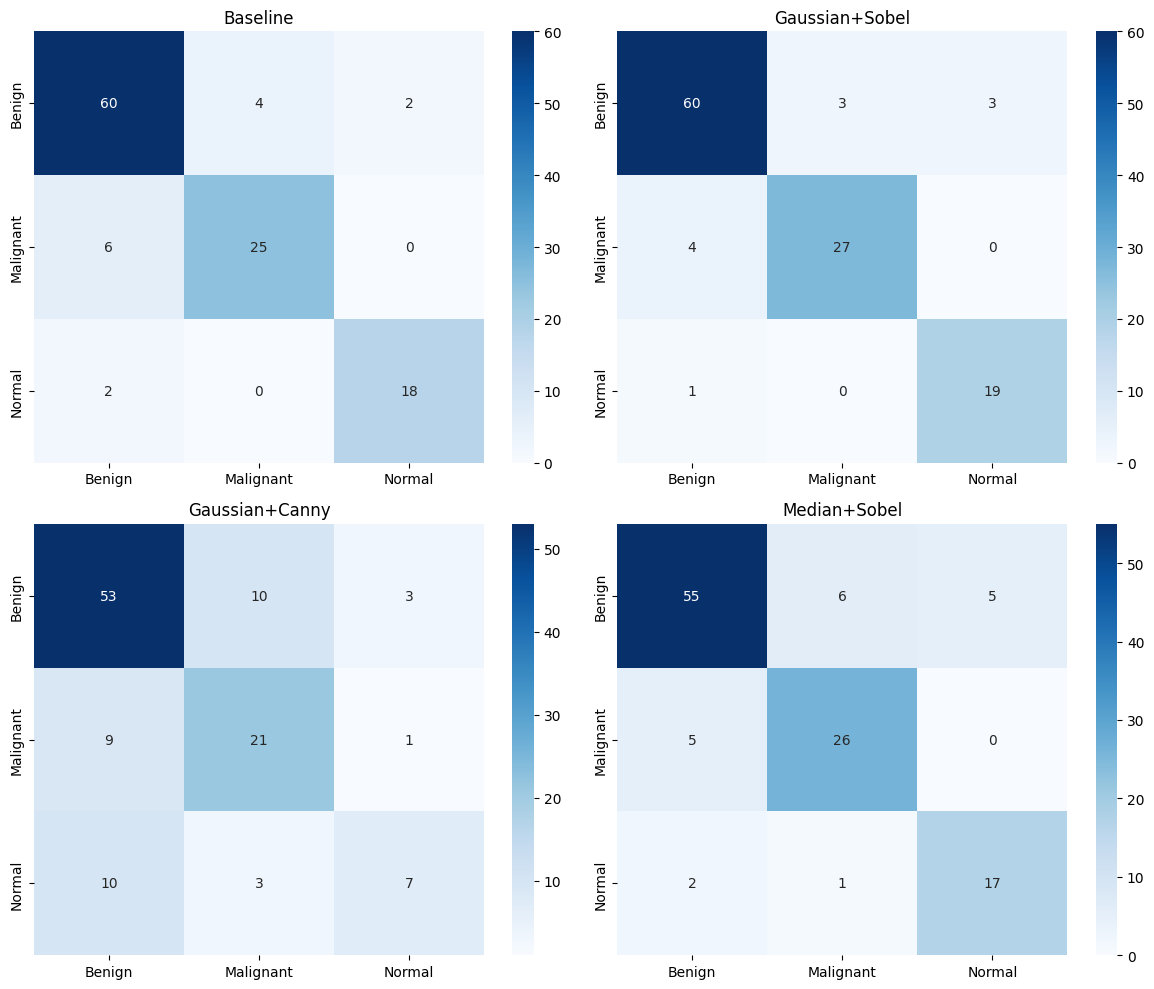

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

results = {
    'Baseline': results_baseline,
    'Gaussian+Sobel': results_gaussian_sobel,
    'Gaussian+Canny': results_gaussian_canny,
    'Median+Sobel': results_median_sobel,
}

print("Perbandingan 4 skenario: \n")
for name, res in results.items():
    print(f"{name}:")
    print(f"Accuracy: {res['accuracy']*100:.2f}%")
    print(f"Malignant - Precision: {res['precision'][1]*100:.2f}%, Recall: {res['recall'][1]*100:.2f}%, F1: {res['f1'][1]*100:.2f}%\n")

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, (name, res) in enumerate(results.items()):
    row, col = i // 2, i % 2
    sns.heatmap(res['cm'], annot=True, fmt='d', cmap='Blues',
                xticklabels=['Benign', 'Malignant', 'Normal'],
                yticklabels=['Benign', 'Malignant', 'Normal'],
                ax=axes[row, col])
    axes[row, col].set_title(name)
plt.tight_layout()
plt.show()

Perbandingan 4 skenario: 

Baseline:
Accuracy: 88.03%
Malignant - Precision: 86.21%, Recall: 80.65%, F1: 83.33%

Gaussian+Sobel:
Accuracy: 90.60%
Malignant - Precision: 90.00%, Recall: 87.10%, F1: 88.52%

Gaussian+Canny:
Accuracy: 69.23%
Malignant - Precision: 61.76%, Recall: 67.74%, F1: 64.62%

Median+Sobel:
Accuracy: 83.76%
Malignant - Precision: 78.79%, Recall: 83.87%, F1: 81.25%



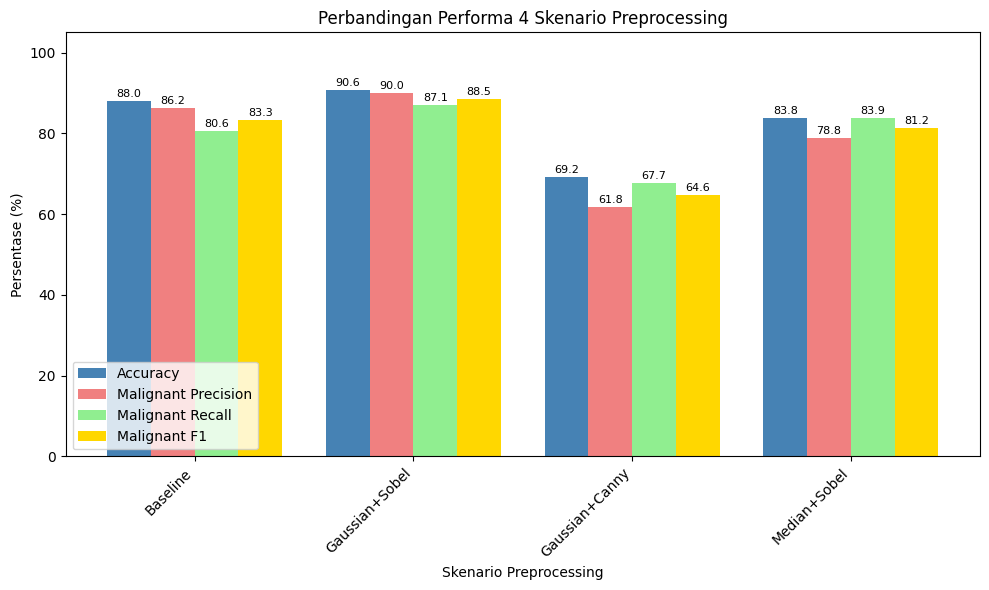

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

results = {
    'Baseline': results_baseline,
    'Gaussian+Sobel': results_gaussian_sobel,
    'Gaussian+Canny': results_gaussian_canny,
    'Median+Sobel': results_median_sobel,
}

print("Perbandingan 4 skenario: \n")
for name, res in results.items():
    print(f"{name}:")
    print(f"Accuracy: {res['accuracy']*100:.2f}%")
    print(f"Malignant - Precision: {res['precision'][1]*100:.2f}%, Recall: {res['recall'][1]*100:.2f}%, F1: {res['f1'][1]*100:.2f}%\n")

fig, ax = plt.subplots(figsize=(10, 6))
scenarios = list(results.keys())
x = np.arange(len(scenarios))
width = 0.2

acc = [results[s]['accuracy']*100 for s in scenarios]
mal_prec = [results[s]['precision'][1]*100 for s in scenarios]
mal_rec = [results[s]['recall'][1]*100 for s in scenarios]
mal_f1 = [results[s]['f1'][1]*100 for s in scenarios]

ax.bar(x - 1.5*width, acc, width, label='Accuracy', color='steelblue')
ax.bar(x - 0.5*width, mal_prec, width, label='Malignant Precision', color='lightcoral')
ax.bar(x + 0.5*width, mal_rec, width, label='Malignant Recall', color='lightgreen')
ax.bar(x + 1.5*width, mal_f1, width, label='Malignant F1', color='gold')

ax.set_xlabel('Skenario Preprocessing')
ax.set_ylabel('Persentase (%)')
ax.set_title('Perbandingan Performa 4 Skenario Preprocessing')
ax.set_xticks(x)
ax.set_xticklabels(scenarios, rotation=45, ha='right')
ax.legend()
ax.set_ylim(0, 105)

for i, (a, p, r, f1) in enumerate(zip(acc, mal_prec, mal_rec, mal_f1)):
    ax.text(i - 1.5*width, a + 1, f'{a:.1f}', ha='center', fontsize=8)
    ax.text(i - 0.5*width, p + 1, f'{p:.1f}', ha='center', fontsize=8)
    ax.text(i + 0.5*width, r + 1, f'{r:.1f}', ha='center', fontsize=8)
    ax.text(i + 1.5*width, f1 + 1, f'{f1:.1f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

# test sample skenario terbaik

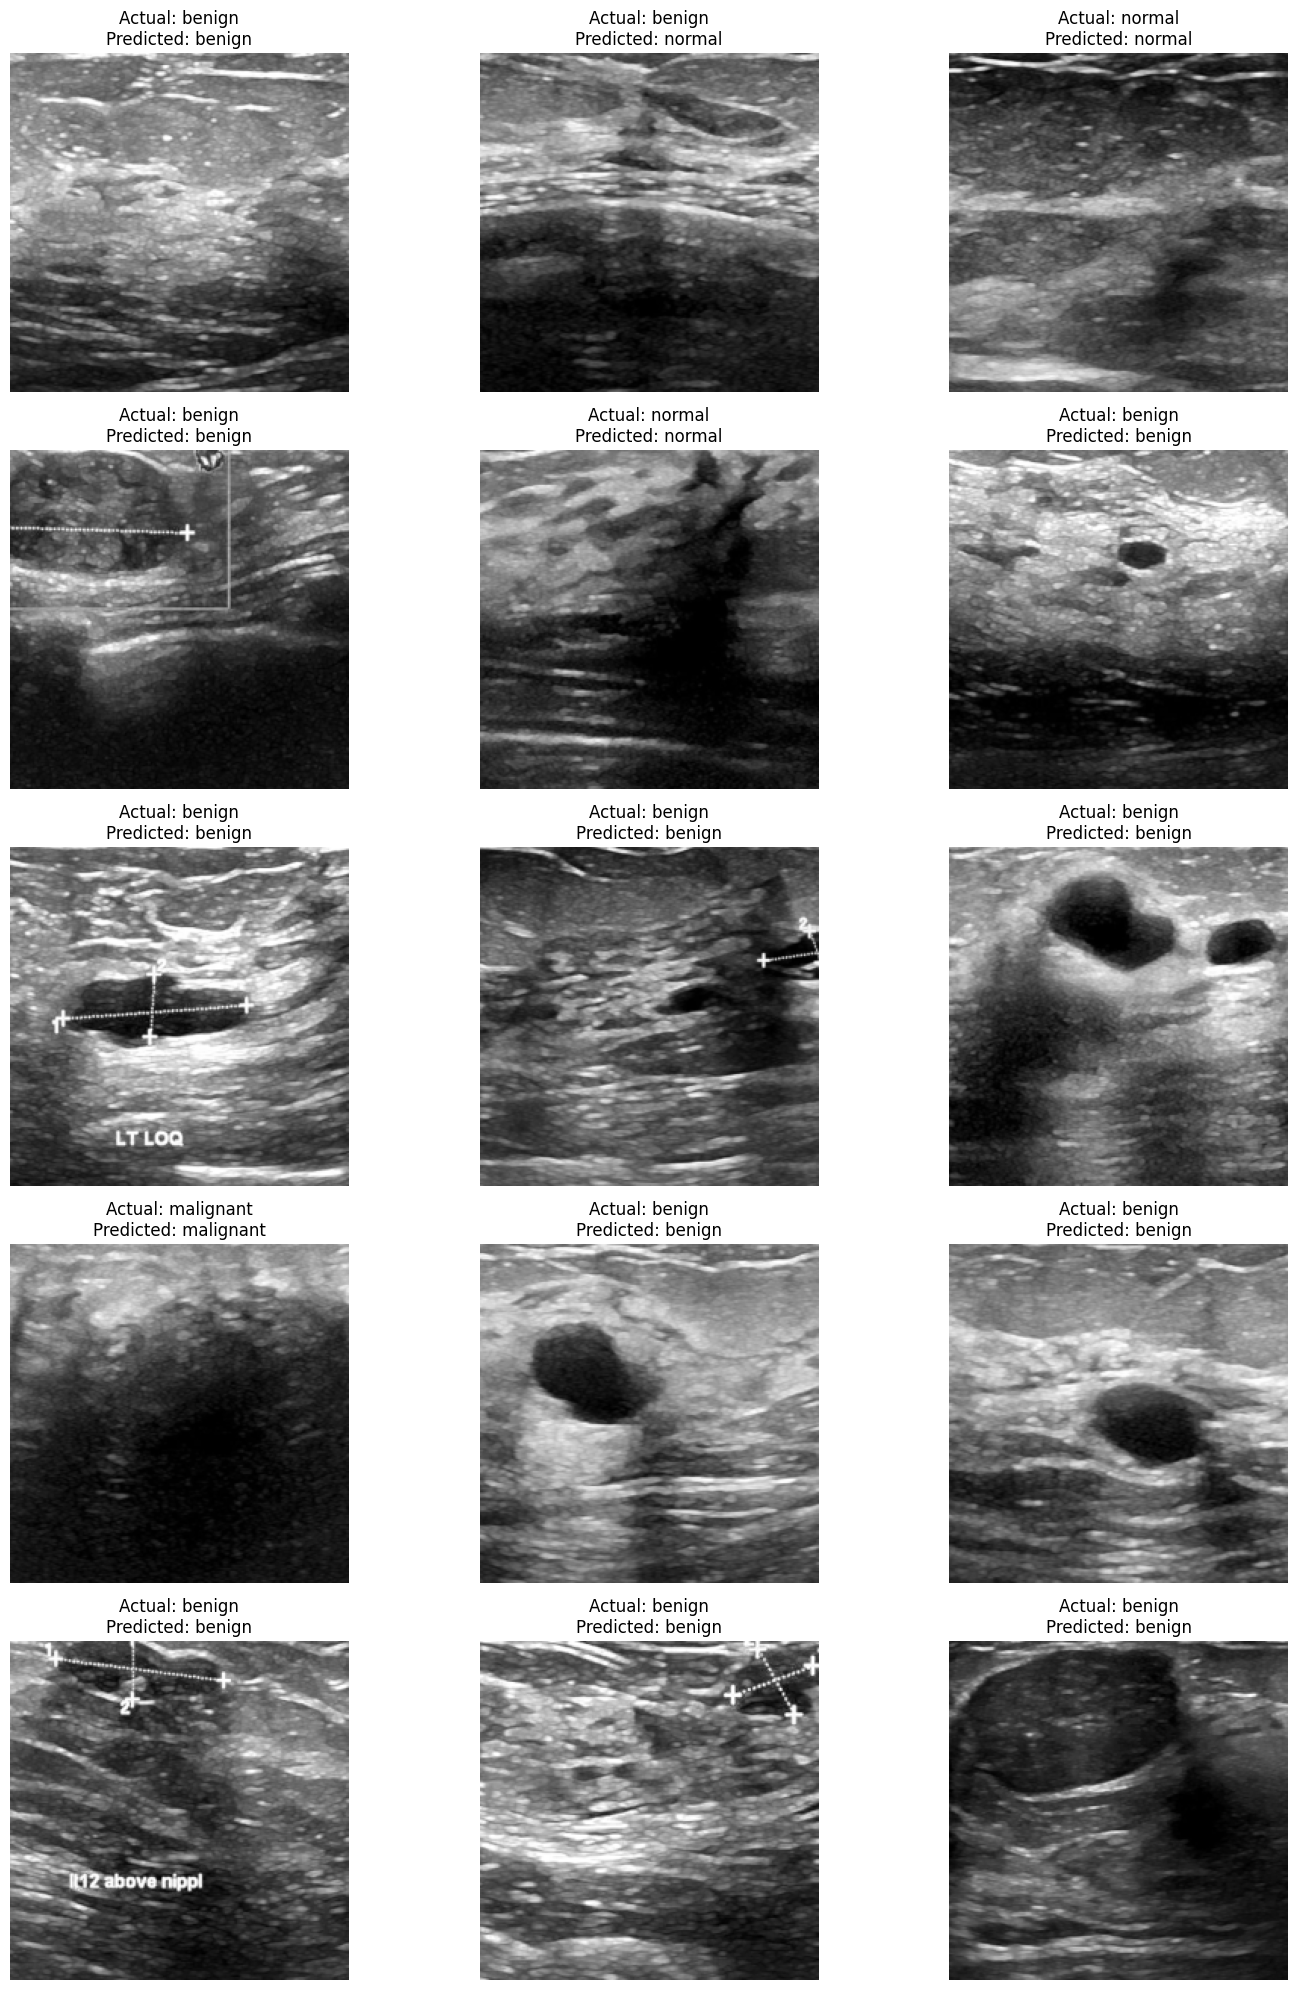

In [ ]:
from torch.utils.data import DataLoader

class_names = ['benign', 'malignant', 'normal']

data_transforms_g_sobel = create_data_transforms(preprocessing_gaussian_sobel)
dataloaders_g_sobel, _, _ = create_dataloaders("Gaussian_Sobel", data_transforms_g_sobel)
test_dataloader = DataLoader(dataloaders_g_sobel['test'].dataset, batch_size=15, shuffle=True, num_workers=2)

inputs, labels = next(iter(test_dataloader))
inputs, labels = inputs.to(device), labels.to(device)
grayscale_images = inputs.cpu().numpy().mean(axis=1)

with torch.no_grad():
    model_g_sobel.eval()
    outputs = model_g_sobel(inputs)
    _, preds = torch.max(outputs, 1)

plt.figure(figsize=(15, 20))
for i in range(15):
    ax = plt.subplot(5, 3, i + 1)
    ax.axis('off')
    ax.set_title(f'Actual: {class_names[labels[i]]}\nPredicted: {class_names[preds[i]]}')
    plt.imshow(grayscale_images[i], cmap='gray')
plt.tight_layout()
plt.show()

# Save model file

In [ ]:
torch.save(model_g_sobel, "/kaggle/working/DenseNet121_model.keras")
print(f'Model saved in {working_dir}')

Model saved in /kaggle/working
